# EDA da API da Câmara

21/10/2026 — tema ainda em definição. Este notebook reaproveita a rede de concordância do projeto e explora outros recursos para apoiar a escolha do novo tema. O relatório completo está em `resultados_eda/RELATORIO_EDA.md`. Nenhum modelo foi treinado.

## 1. Recorte e acesso

Agosto/2023, para aproveitar o período do código existente. Somente o Plenário na análise de votos. A amostra de decisões é enriquecida por descrições com placar; proposições e eventos são recortes parciais. Não inferir resultados gerais da legislatura.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
BASE = Path.cwd()
if not (BASE / "eda_api.py").exists():
    BASE = BASE / "DEPUTADOS"
sys.path.insert(0, str(BASE))
from camara_api import CamaraAPI
from eda_api import collect, analyse, vote_frame, quality_table
OUT = BASE / "resultados_eda"
RECOLETAR = False  # True consulta a API; False abre o EDA já executado.
if RECOLETAR:
    api = CamaraAPI(BASE / "cache_eda", max_requests=200)
    data = collect(api, "2023-08-01", "2023-08-31", 30, 12)
    OUT.mkdir(exist_ok=True)
    (OUT / "coleta.json").write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    summary = analyse(data, OUT)
else:
    summary = json.loads((OUT / "resumo.json").read_text(encoding="utf-8"))
summary["amostragem"]

Out[1]: 
{'universo_metadados': 141,
 'descricoes_com_placar': 31,
 'descricoes_sem_placar': 110,
 'selecionadas_com_placar': 30,
 'selecionadas_sem_placar': 6,
 'metodo': 'Aleatória semente 42 dentro das descrições com placar; semente 43 nas demais. Amostra exploratória enriquecida, não representativa da produção legislativa.'}


## 2. Inventário e cobertura

“Completo” significa que a paginação terminou para os filtros daquela consulta. Não significa cobrir toda a Câmara.

In [2]:
pd.DataFrame(summary["catalogo"]).T[["registros", "paginas", "completo", "rota"]]

Out[2]: 
                 registros paginas completo                              rota
orgaos                   1       1     True                           /orgaos
deputados              523       6     True                        /deputados
votacoes               141       2     True                         /votacoes
proposicoes            100       1    False                      /proposicoes
eventos                 99       1    False                          /eventos
temas_referencia        32       1     True  /referencias/proposicoes/codTema


In [3]:
coverage = pd.read_csv(OUT / "cobertura_consultas.csv")
coverage.groupby("tipo").agg(consultas=("id","size"), registros=("registros","sum"), completas=("completo","sum"))

Out[3]: 
             consultas  registros  completas
tipo                                        
autores             12         12         12
despesas             3          0          3
orientacoes         24        240         24
presencas            3         88          3
temas               12         29         12
tramitacoes         12        147         12
votos               36      11662         36


## 3. Qualidade

Não confundir lista vazia com falha HTTP ou atividade zero. Deputados são identificados pelo ID, não pelo nome nem pelo partido atual.

In [4]:
quality = pd.read_csv(OUT / "qualidade_campos.csv")
quality[quality.ausentes > 0]

Out[4]: 
      recurso                campo  registros  ausentes  fracao_ausente
8   deputados                email        523        57        0.108987
15   votacoes            uriEvento        141        16        0.113475
16   votacoes     proposicaoObjeto        141        98        0.695035
17   votacoes  uriProposicaoObjeto        141        98        0.695035
19   votacoes            aprovacao        141         3        0.021277
31    eventos          dataHoraFim         99        17        0.171717
35    eventos         localExterno         99        91        0.919192
37    eventos          urlRegistro         99        28        0.282828
38    eventos     localCamara.nome         99         8        0.080808
39    eventos   localCamara.predio         99        99        1.000000
40    eventos     localCamara.sala         99        99        1.000000
41    eventos    localCamara.andar         99        99        1.000000


In [5]:
pd.Series({k:summary[k] for k in ["registros_votos", "votacoes_com_votos", "deputados_com_votos", "ids_ausentes", "duplicatas_chave", "chaves_conflitantes", "deputados_com_mais_de_um_partido"]})

Out[5]: 
registros_votos                     11662
votacoes_com_votos                     28
deputados_com_votos                   513
ids_ausentes                            0
duplicatas_chave                        0
chaves_conflitantes                     0
deputados_com_mais_de_um_partido        3
dtype: int64


## 4. Distribuição de votos e decisões quase consensuais

Critério exploratório: minoria / (Sim + Não). Menos de 10% caracteriza a categoria quase consensual usada neste piloto, sem constituir uma definição política universal.

Sim          8831
Não          2788
Artigo 17      26
Abstenção      17
Name: registros, dtype: int64

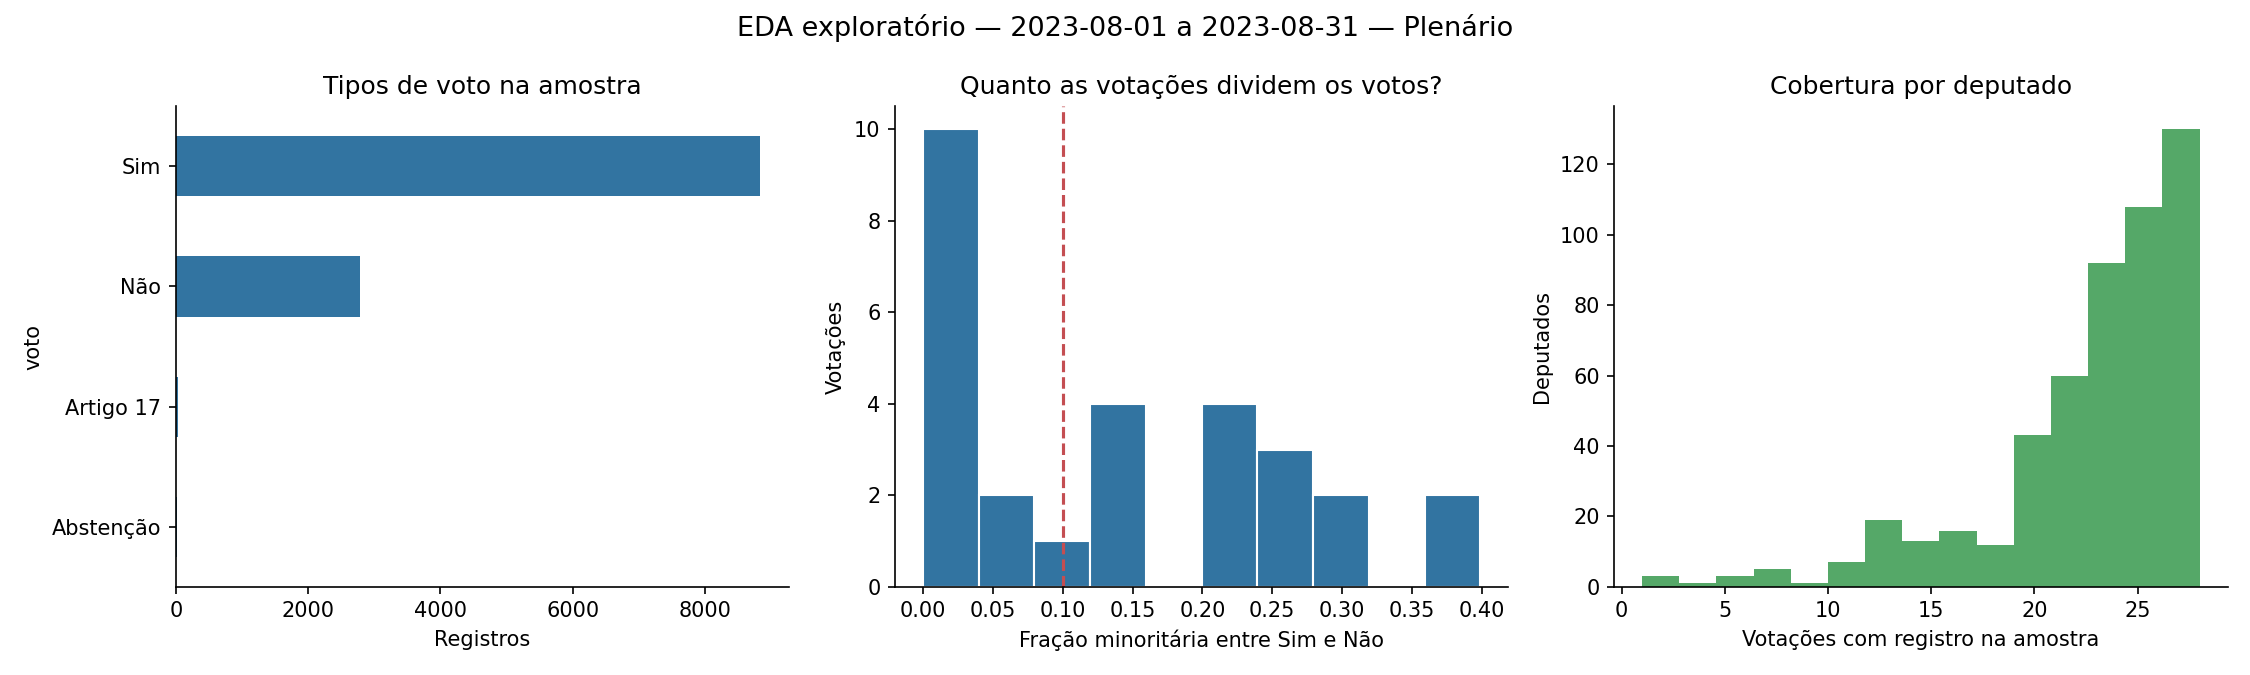

In [6]:
display(pd.Series(summary["tipos_voto"], name="registros"))
display(Image(filename=str(OUT / "figuras/01_cobertura_e_votos.png")))

## 5. Redes e sensibilidade

Concordância usa somente decisões em comum. São comparados tipos de voto, limiar e mínimo de observações. Louvain é calculado nas três redes de referência (70%, mínimo 5); campos vazios nas outras configurações indicam etapa não executada, não zero comunidades.

In [7]:
sensitivity = pd.read_csv(OUT / "sensibilidade_grafos.csv")
sensitivity[(sensitivity.minimo_comuns == 5)]

Out[7]: 
                 tratamento  minimo_comuns  ...  modularidade  ARI_partidos
0            Todos os tipos              5  ...      0.108614      0.075715
1            Todos os tipos              5  ...           NaN           NaN
2            Todos os tipos              5  ...           NaN           NaN
9           Somente Sim/Não              5  ...      0.108779      0.075332
10          Somente Sim/Não              5  ...           NaN           NaN
11          Somente Sim/Não              5  ...           NaN           NaN
18  Sim/Não e minoria >=10%              5  ...      0.219499      0.201342
19  Sim/Não e minoria >=10%              5  ...           NaN           NaN
20  Sim/Não e minoria >=10%              5  ...           NaN           NaN

[9 rows x 11 columns]


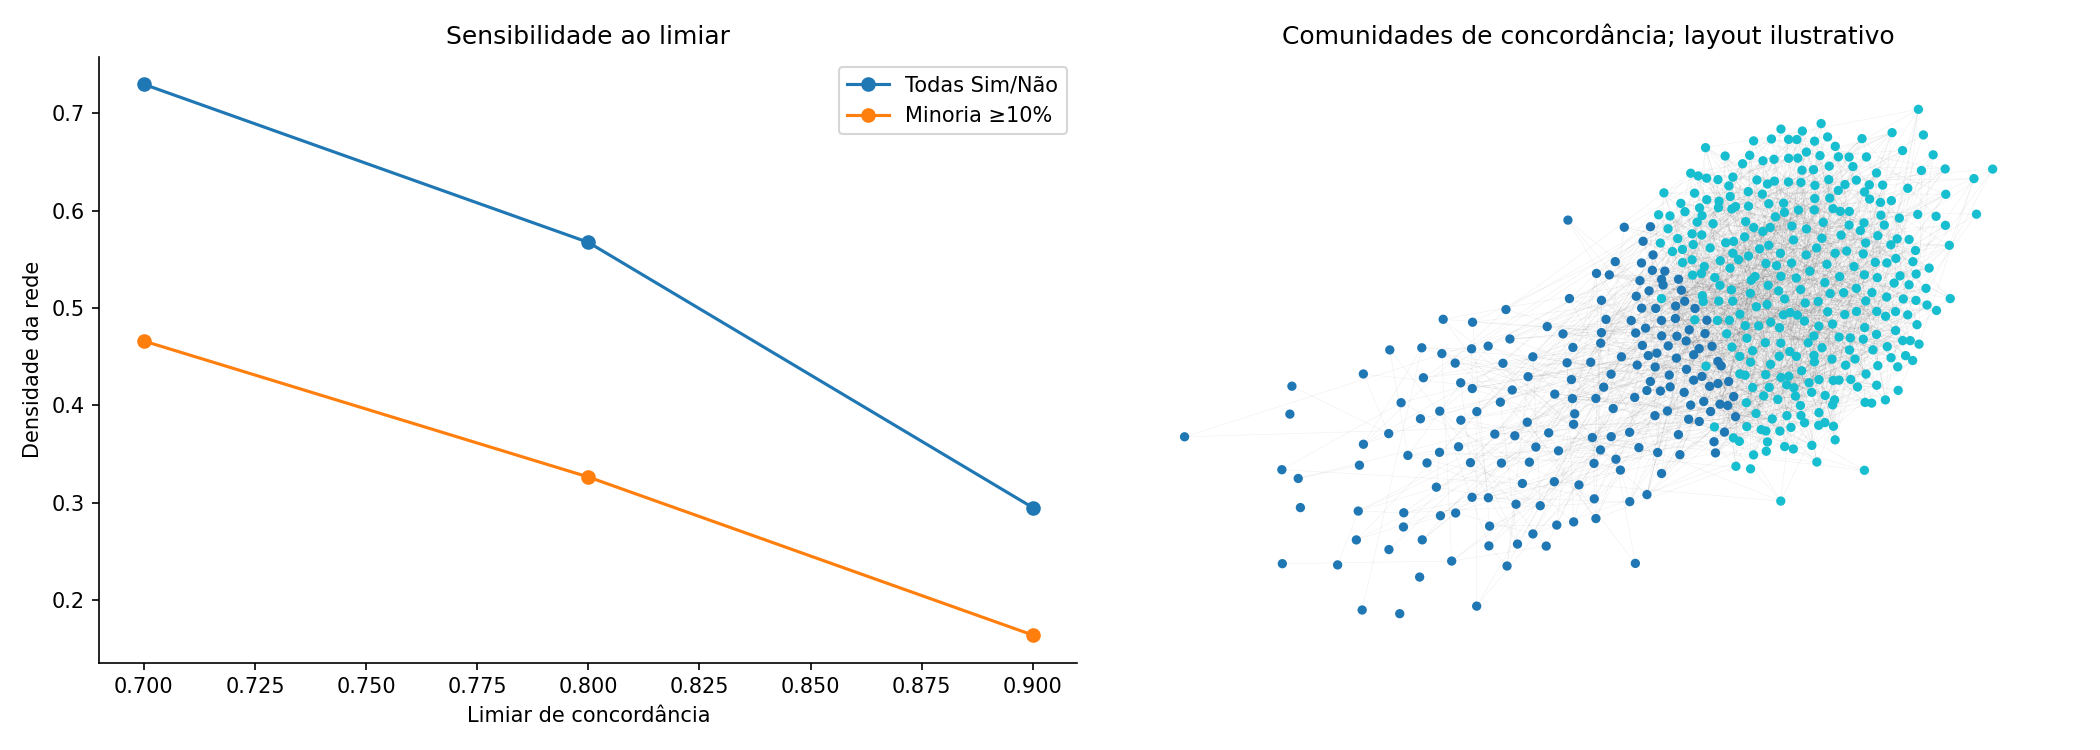

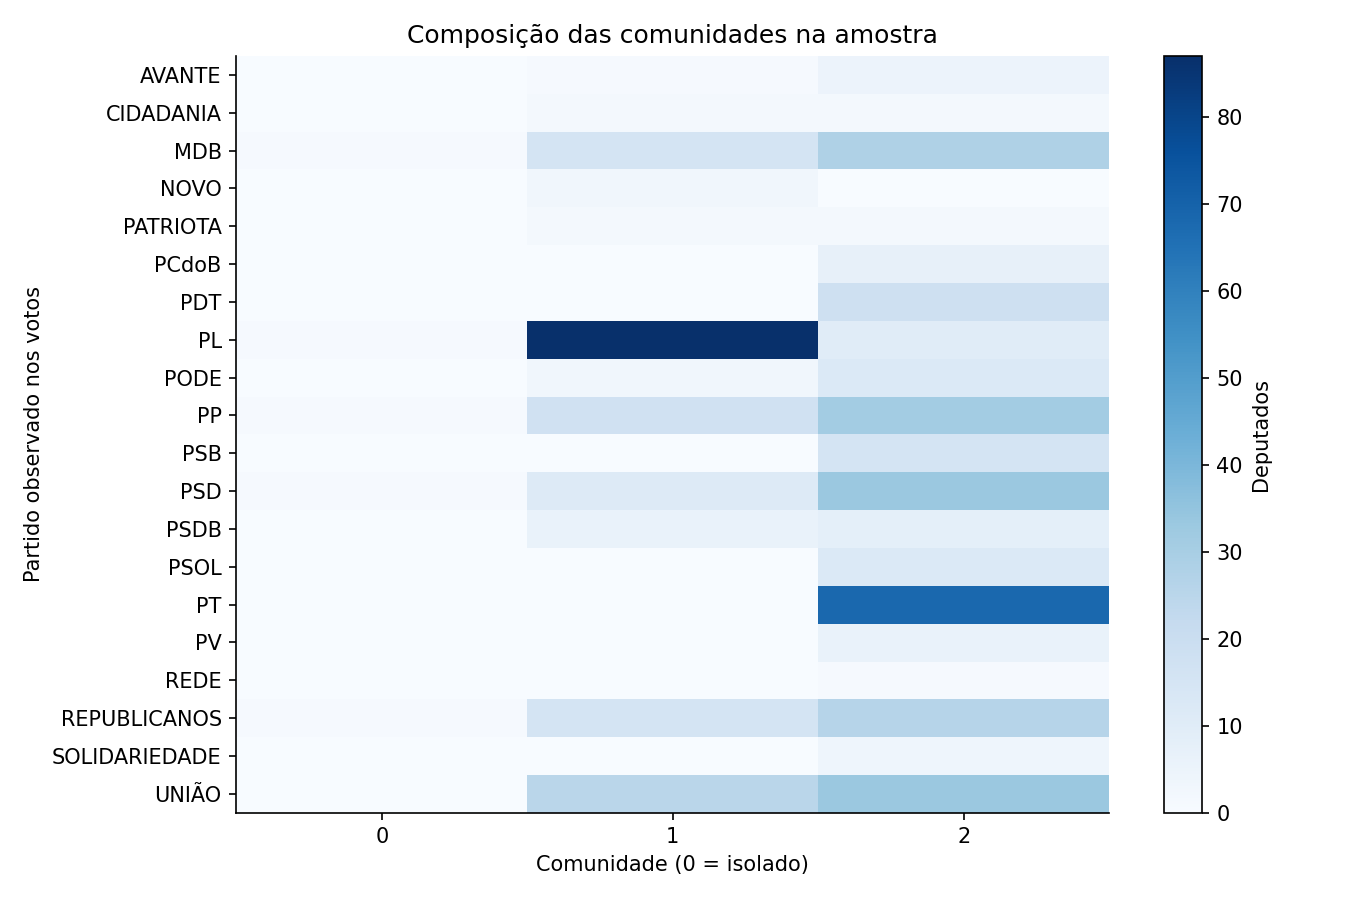

In [8]:
display(Image(filename=str(OUT / "figuras/02_sensibilidade_e_rede.png")))
display(Image(filename=str(OUT / "figuras/03_partidos_comunidades.png")))

Retirar decisões quase consensuais altera tanto as observações disponíveis quanto as conexões. A diferença de densidade não é uma estimativa causal. Comunidades não são sinônimo de partidos, ideologia ou influência. O desenho usa apenas uma amostra de arestas; as métricas usam todas.

## 6. Orientações de partido

Somente liderança partidária direta (`P`) com orientação Sim/Não foi associada ao partido observado no voto. Blocos e federações precisam de mapeamento histórico. A cobertura de 15,8% impede generalizar a taxa de adesão para toda a Câmara.

In [9]:
display(pd.read_csv(OUT / "adesao_orientacao_direta.csv"))
print("Cobertura direta:", f"{summary["fracao_votos_binarios_com_orientacao_direta"]:.1%}")

Cobertura direta: 15.8%


,partido,votos_comparaveis,taxa_adesao
0,NOVO,72,1.000000
1,PL,1764,0.888322


## 7. Proposições, eventos e despesas

Há temas nos 12 PL consultados, mas todos têm autor único no recorte. Tramitações retornadas podem incluir fatos posteriores ao mês de apresentação. Três consultas históricas de despesas vieram vazias; a viabilidade desse caminho permanece inconclusiva.

In [10]:
display(pd.read_csv(OUT / "temas_proposicoes_amostra.csv").head(12))
display(pd.read_csv(OUT / "autores_proposicoes_amostra.csv").head(12))
display(pd.Series({k:summary[k] for k in ["proposicoes_enriquecidas", "proposicoes_com_tema", "proposicoes_com_multiplos_autores", "registros_tramitacoes", "registros_presenca_eventos", "registros_despesas"]}))

,idProposicao,codTema,tema,relevancia
0,2374676,57,Defesa e Segurança,0
1,2374676,44,Direitos Humanos e Minorias,0
2,2374899,34,Administração Pública,0
3,2374899,43,Direito Penal e Processual Penal,0
4,2374914,62,"Ciência, Tecnologia e Inovação",0
5,2374914,37,Comunicações,0
6,2374914,44,Direitos Humanos e Minorias,0
7,2374934,44,Direitos Humanos e Minorias,0
8,2374934,52,Previdência e Assistência Social,0
9,2374934,56,Saúde,0


,idProposicao,uri,nome,codTipo,tipo,ordemAssinatura,proponente
0,2374676,https://dadosabertos.camara.leg.br/api/v2/depu...,Lázaro Botelho,10000,Deputado(a),1,1
1,2374899,https://dadosabertos.camara.leg.br/api/v2/depu...,Luciano Ducci,10000,Deputado(a),1,1
2,2374914,https://dadosabertos.camara.leg.br/api/v2/depu...,Capitão Alberto Neto,10000,Deputado(a),1,1
3,2374934,https://dadosabertos.camara.leg.br/api/v2/depu...,Ricardo Silva,10000,Deputado(a),1,1
4,2374956,https://dadosabertos.camara.leg.br/api/v2/depu...,Kim Kataguiri,10000,Deputado(a),1,1
5,2375078,https://dadosabertos.camara.leg.br/api/v2/depu...,Fábio Teruel,10000,Deputado(a),1,1
6,2375149,https://dadosabertos.camara.leg.br/api/v2/depu...,Alberto Fraga,10000,Deputado(a),1,1
7,2375258,https://dadosabertos.camara.leg.br/api/v2/depu...,Guilherme Boulos,10000,Deputado(a),1,1
8,2375602,https://dadosabertos.camara.leg.br/api/v2/depu...,Laura Carneiro,10000,Deputado(a),1,1
9,2375745,https://dadosabertos.camara.leg.br/api/v2/depu...,Silas Câmara,10000,Deputado(a),1,1


proposicoes_enriquecidas              12
proposicoes_com_tema                  12
proposicoes_com_multiplos_autores      0
registros_tramitacoes                147
registros_presenca_eventos            88
registros_despesas                     0
dtype: int64

## 8. Decisão com o orientador

1. Comparar a robustez das comunidades aos critérios de construção da rede.
2. Ampliar para a evolução mensal das afinidades de voto.
3. Estudar adesão às bancadas após resolver blocos e federações.
4. Explorar classificação temática de ementas se a direção preferida for IA textual.

Definir pergunta, contribuição, período, unidade de análise e critérios de avaliação antes da coleta definitiva. Consultar o relatório para limitações, roteiro de perguntas e fontes.

## Fontes

- [API oficial](https://dadosabertos.camara.leg.br/swagger/api.html)
- [OpenAPI](https://dadosabertos.camara.leg.br/api/v2/api-docs)
- [Conceitos e limites de votações](https://dadosabertos.camara.leg.br/howtouse/2020-02-07-dados-votacoes.html)
- Código anterior da pasta DEPUTADOS, commit 16adb81230293d4a02ab70c83dceb86e4241ae32.

Os CSV, o manifesto e as figuras correspondem à execução deste piloto, não a uma base final congelada para o TCC.